# Day 7: Error analysis

Where and why does the fine-tuned model of day 5 make mistakes? The data is the same 20% split as on days 4-6: 9,123 tweets the model never saw in training.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

from itg_transformers.config import FINE_TUNED_DIR, LABELS, RESULTS_DIR
from itg_transformers.data import clean_text, load_split
from itg_transformers.eda import TWITTER_PATTERNS, matches, pattern_error_rates
from itg_transformers.embeddings import pick_device
from itg_transformers.finetuning import load_classifier
from itg_transformers.inference import predict_fine_tuned
from itg_transformers.tokenization import load_tokenizer

pd.set_option("display.max_colwidth", None)

## 1. Errors of the model

Predictions of day 6, recomputed: `predict_fine_tuned` on the 20% split takes a few seconds. The confidence of every prediction (the probability of the predicted class) is kept as well.

In [2]:
device = pick_device()
model_ft = load_classifier(str(FINE_TUNED_DIR))
model_ft.to(device)  # ty: ignore[invalid-argument-type]
tokenizer = load_tokenizer(str(FINE_TUNED_DIR))

df = load_split("train")
_, test_df, _, _ = train_test_split(
    df, df["label"], test_size=0.2, random_state=42, stratify=df["label"]
)
test_texts = test_df["text"].tolist()
test_labels = test_df["label"].tolist()

preds_ft_all = predict_fine_tuned(test_texts, model_ft, tokenizer, clean_text)
y_pred_ft = [p["prediction"] for p in preds_ft_all]

df_test = pd.DataFrame(
    {
        "text": test_texts,
        "true_label": test_labels,
        "pred_label": y_pred_ft,
        "confidence": [p["probabilities"].max() for p in preds_ft_all],
    },
    index=test_df.index,
)
errors = df_test[df_test["true_label"] != df_test["pred_label"]]
error_rate = len(errors) / len(df_test)
print(f"Total errors: {len(errors)} of {len(df_test)} ({error_rate:.1%})")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Total errors: 2628 of 9123 (28.8%)


### False positives and false negatives

The task's code is written for labels where 1 means positive. Ours are `0 = negative, 1 = neutral, 2 = positive`, so its `pred_label == 1 & true_label == 0` would select "predicted neutral, was negative". Keeping the meaning of the task ("said good, was bad" and the reverse), with our labels:

- **false positive**: predicted positive (2), actually negative (0);
- **false negative**: predicted negative (0), actually positive (2).

In [3]:
NEGATIVE, NEUTRAL, POSITIVE = 0, 1, 2

fp = errors[
    (errors["pred_label"] == POSITIVE) & (errors["true_label"] == NEGATIVE)
]
fn = errors[
    (errors["pred_label"] == NEGATIVE) & (errors["true_label"] == POSITIVE)
]

print(f"Total errors: {len(errors)}")
print(f"False Positives: {len(fp)}")
print(f"False Negatives: {len(fn)}")

Total errors: 2628
False Positives: 91
False Negatives: 106


With three classes these two are only a small part of the errors. All six kinds of mistakes:

In [4]:
kinds = (
    errors.groupby(["true_label", "pred_label"])
    .agg(count=("text", "size"), mean_confidence=("confidence", "mean"))
    .reset_index()
)
kinds["error"] = (
    "true "
    + kinds["true_label"].map(LABELS)
    + " → predicted "
    + kinds["pred_label"].map(LABELS)
)
kinds["share of errors"] = kinds["count"] / len(errors)
kinds.set_index("error")[
    ["count", "share of errors", "mean_confidence"]
].sort_values("count", ascending=False).round(2)

,count,share of errors,mean_confidence
error,,,
true neutral → predicted positive,830,0.32,0.76
true positive → predicted neutral,730,0.28,0.75
true negative → predicted neutral,454,0.17,0.75
true neutral → predicted negative,417,0.16,0.76
true positive → predicted negative,106,0.04,0.69
true negative → predicted positive,91,0.03,0.74


## 2. Examples and text length

The first five false positives and false negatives, as in the task, with the full text:

In [5]:
def show(rows, title):
    print(f"\n=== {title} ===")
    for _, row in rows.head(5).iterrows():
        print(f"\nText: {row['text']}")
        print(
            f"True label: {LABELS[row['true_label']]}, "
            f"predicted: {LABELS[row['pred_label']]} "
            f"({row['confidence']:.2f})"
        )


show(fp, "FALSE POSITIVES (said good, was bad)")
show(fn, "FALSE NEGATIVES (said bad, was good)")


=== FALSE POSITIVES (said good, was bad) ===

Text: Heather is like the serpent in the garden trying 2 entice info from McBain! Michael Easton, dont ever go away that long! Watching Tues #GH.
True label: negative, predicted: positive (0.55)

Text: BAY HEAD, N.J./BOSTON, Nov 2 (Reuters) - The people of the Jersey Shore may feel alone in the world right now, t...
True label: negative, predicted: positive (0.72)

Text: First it turns out Meek Mill is an Arsenal fan, now this. I'm finding a new club. This is a Barcelona account now.
True label: negative, predicted: positive (0.70)

Text: Thanks manager for putting me on the schedule for Sunday"
True label: negative, predicted: positive (0.93)

Text: The best way to find Malaysia Airlines Flight MH370 may be with Michelle Obama's arms.
True label: negative, predicted: positive (0.94)

=== FALSE NEGATIVES (said bad, was good) ===

Text: Gambled on Chocolate Day as a successful theme day at work..turns out chdn DO like chocolate. Wed. is Gro

What the ten examples have in common:

- **Sarcasm**: "Thanks manager for putting me on the schedule for Sunday" and the joke about Michelle Obama's arms are polite or funny on the surface and negative in meaning. The model reads the surface, with 93-94% confidence.
- **Negative words used positively**: "Damn. I would totally buy the Sun for this", "I have lost the 1 kg". `damn` and `lost` pull towards negative although the tweets are pleased.
- **Debatable labels**: "Harper does not play well with others" labelled positive, or the sandwich mix-up ending in "so happy tues guys", which reads ironic. Here the model may well be right and the label wrong, as the EDA found for 2-4 of every 10 tweets.
- **News with a sentiment label**: the Reuters headline about the Jersey Shore is labelled negative because of its topic, not its wording.

Most of these mistakes come with modest confidence (0.55-0.75); the sarcastic ones are the exception.

### Length of misclassified texts

In [6]:
df_test["text_length"] = df_test["text"].str.len()
df_test["correct"] = df_test["true_label"] == df_test["pred_label"]
errors = df_test[~df_test["correct"]]

print(
    f"Mean length of misclassified texts: {errors['text_length'].mean():.0f}"
)
print(f"Mean length of all texts: {df_test['text_length'].mean():.0f}")

Mean length of misclassified texts: 108
Mean length of all texts: 106


A mean hides the shape of the distribution. The error rate by length bucket answers the real question, whether long or short tweets are harder:

In [7]:
buckets = pd.qcut(df_test["text_length"], q=5)
by_length = df_test.groupby(buckets, observed=True).agg(
    tweets=("text", "size"),
    error_rate=("correct", lambda correct: 1 - correct.mean()),
)
by_length.round(3)

,tweets,error_rate
text_length,,
"(21.999, 83.0]",1890,0.245
"(83.0, 104.0]",1824,0.295
"(104.0, 115.0]",1851,0.276
"(115.0, 130.0]",1815,0.311
"(130.0, 143.0]",1743,0.317


Misclassified tweets are only slightly longer on average (108 against 106 characters), but the buckets show a steady trend: the shortest fifth of tweets has an error rate of 24.5%, the longest fifth 31.7%. Longer tweets more often mix several statements and sentiments, and the model has to settle on one label. Truncation plays no role: the longest tweet of the split has 56 tokens, below `max_length` 64.

## 3. Patterns behind the errors

### Confidence

Is the model less sure when it is wrong? And when it says 95%, is it right 95% of the time?

In [8]:
df_test.groupby("correct")["confidence"].describe()[
    ["count", "mean", "25%", "50%", "75%"]
].round(3)

,count,mean,25%,50%,75%
correct,,,,,
False,2628.0,0.752,0.607,0.762,0.905
True,6495.0,0.880,0.814,0.947,0.987


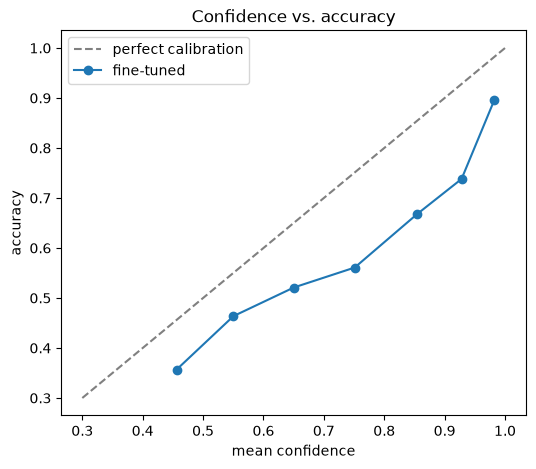

,tweets,mean_confidence,accuracy
confidence,,,
"(0.0, 0.5]",213,0.456,0.357
"(0.5, 0.6]",910,0.550,0.464
"(0.6, 0.7]",858,0.650,0.521
"(0.7, 0.8]",1034,0.751,0.561
"(0.8, 0.9]",1389,0.855,0.668
"(0.9, 0.95]",1172,0.928,0.738
"(0.95, 1.0]",3547,0.982,0.896


In [9]:
bins = [0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0]
calibration = df_test.groupby(
    pd.cut(df_test["confidence"], bins), observed=True
).agg(
    tweets=("text", "size"),
    mean_confidence=("confidence", "mean"),
    accuracy=("correct", "mean"),
)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0.3, 1], [0.3, 1], "--", color="gray", label="perfect calibration")
ax.plot(
    calibration["mean_confidence"],
    calibration["accuracy"],
    "o-",
    label="fine-tuned",
)
ax.set_xlabel("mean confidence")
ax.set_ylabel("accuracy")
ax.set_title("Confidence vs. accuracy")
ax.legend()
plt.show()

calibration.round(3)

Errors do come with lower confidence (median 0.76 against 0.95), so confidence is useful: a low-confidence prediction deserves a second look. But the model is **overconfident** at every level: when it says 0.85 it is right 67% of the time, when it says 0.93 only 74%, and even at 0.98 it is wrong one time in ten. The curve lies below the diagonal everywhere. A shown probability of 99% in the demo should be read with that in mind.

### Hypotheses from the EDA

Error rate of tweets with and without a pattern. Negation and two topics that the EDA found tied to the negative class are added to the Twitter patterns of `00_eda.ipynb`.

In [10]:
patterns = {
    "negation": (
        r"\b(?:not|no|never|nothing|nobody|dont|cant|wont|isnt)\b|n't\b"
    ),
    "topic: islam / ira / isis": r"(?i)\b(?:muslims?|islam|ira|hebdo|isis)\b",
    **{
        name: TWITTER_PATTERNS[name]
        for name in [
            "elongated_word",
            "caps_word",
            "hashtag",
            "user_mention",
            "repeated_punct",
            "emoticon",
        ]
    },
}
rates = pattern_error_rates(df_test["text"], df_test["correct"], patterns)
rates["difference"] = rates["error_rate_with"] - rates["error_rate_without"]
rates.sort_values("difference", ascending=False).round(3)

,tweets,error_rate_with,error_rate_without,difference
negation,1525.0,0.374,0.271,0.103
topic: islam / ira / isis,218.0,0.385,0.286,0.100
elongated_word,176.0,0.352,0.287,0.065
caps_word,2046.0,0.282,0.290,-0.008
user_mention,2610.0,0.281,0.291,-0.010
hashtag,1679.0,0.274,0.291,-0.017
repeated_punct,515.0,0.235,0.291,-0.056
emoticon,287.0,0.178,0.292,-0.114


Two hypotheses can only be checked on the official test split: train has no emoji at all, and the topic bias matters most on new tweets. Predictions on test:

In [11]:
official = load_split("test")
official_preds = predict_fine_tuned(
    official["text"].tolist(), model_ft, tokenizer, clean_text
)
official = official.assign(
    pred_label=[p["prediction"] for p in official_preds],
)
official_correct = official["label"] == official["pred_label"]

pattern_error_rates(
    official["text"],
    official_correct,
    {"emoji": TWITTER_PATTERNS["emoji"], "negation": patterns["negation"]},
).round(3)

,tweets,error_rate_with,error_rate_without
emoji,802.0,0.333,0.320
negation,1897.0,0.361,0.313


In [12]:
topic = matches(official["text"], patterns["topic: islam / ira / isis"])
pd.DataFrame(
    {
        "true": official.loc[topic, "label"].map(LABELS).value_counts(),
        "predicted": official.loc[topic, "pred_label"]
        .map(LABELS)
        .value_counts(),
    }
).reindex(list(LABELS.values()))

,true,predicted
negative,66,96
neutral,129,97
positive,6,8


What the EDA expected, checked against the errors:

| hypothesis | result |
|---|---|
| **negation** is hard | confirmed: error rate 37% against 27%, on test 36% against 31% |
| **topics leak into labels** (`muslims`, `ira`, `isis`) | confirmed: error rate 39% against 29%; on test the model calls 96 of these tweets negative where only 66 are, mostly at the expense of neutral |
| **elongated words** (`soooo`) are hard | partly: 35% against 29%, but only 176 tweets |
| **emoji** become `[UNK]` and hurt | not confirmed: 33% against 32% on test, the rest of the tweet carries the sentiment |
| capitals are lost by the uncased model | no effect |

Emoticons like `:)` and repeated `!!` make tweets *easier*: they are explicit sentiment markers that survive tokenization.

The topic result is the most important one. On new tweets about Islam, the IRA or ISIS the model labels neutral reports as negative because training tweets on these topics were mostly negative. It is a bias learned from the data, not from the wording, and it would matter in any real use of the model.

## 4. Saving the analysis

`results/error_analysis.txt` has the structure of the task: counts, examples of false positives and negatives, observations. The observations are the findings of sections 1-3.

In [13]:
def example_lines(rows):
    lines = []
    for _, row in rows.head(5).iterrows():
        lines += [
            "",
            f"Text: {row['text']}",
            f"True: {LABELS[row['true_label']]}, "
            f"predicted: {LABELS[row['pred_label']]} "
            f"(confidence {row['confidence']:.2f})",
        ]
    return lines


observations = [
    "1. 93% of the errors involve the neutral class; negative and positive",
    "   are rarely confused with each other (FP + FN = 7.5% of errors).",
    "   Neutral is also the noisiest class of the labels (see the EDA).",
    "2. Typical causes in the examples: sarcasm (polite or funny wording,",
    "   negative meaning), negative words used positively ('damn', 'lost'),",
    "   news labelled by topic, and labels that are debatable themselves.",
    "3. Negation is hard: error rate 37% with 'not', 'n't', 'never'",
    "   against 27% without.",
    "4. Topic bias: tweets about Islam, the IRA or ISIS have an error rate",
    "   of 39% against 29%; on the official test split the model calls 96",
    "   of them negative where 66 are. Neutral reports on these topics are",
    "   labelled negative because training tweets on them mostly were.",
    "5. Longer tweets are harder: error rate 24.5% for the shortest fifth,",
    "   31.7% for the longest. They mix statements; truncation plays no role.",
    "6. The model is overconfident: at 0.85 confidence it is right 67% of",
    "   the time, at 0.98 only 90%. Errors still have lower confidence",
    "   (median 0.76 against 0.95), so low confidence flags doubtful cases.",
    "7. Not confirmed: emoji (unknown to the uncased vocabulary) and",
    "   capitals do not raise the error rate; emoticons like ':)' lower it.",
]

error_kinds = (
    kinds.set_index("error")[["count", "share of errors"]]
    .sort_values("count", ascending=False)
    .round(2)
)
lines = [
    "=== ERROR ANALYSIS ===",
    "",
    "Fine-tuned DistilBERT on the 20% validation split (9,123 tweets)",
    "False positive: predicted positive, actually negative",
    "False negative: predicted negative, actually positive",
    "",
    f"Total errors: {len(errors)}",
    f"False Positives: {len(fp)}",
    f"False Negatives: {len(fn)}",
    "",
    "All kinds of errors:",
    error_kinds.to_string(),
    "",
    f"Mean length of misclassified texts: {errors['text_length'].mean():.0f}",
    f"Mean length of all texts: {df_test['text_length'].mean():.0f}",
    "",
    "=== FALSE POSITIVE EXAMPLES ===",
    *example_lines(fp),
    "",
    "=== FALSE NEGATIVE EXAMPLES ===",
    *example_lines(fn),
    "",
    "=== OBSERVATIONS ===",
    "",
    *observations,
]
(RESULTS_DIR / "error_analysis.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

=== ERROR ANALYSIS ===

Fine-tuned DistilBERT on the 20% validation split (9,123 tweets)
False positive: predicted positive, actually negative
False negative: predicted negative, actually positive

Total errors: 2628
False Positives: 91
False Negatives: 106

All kinds of errors:
                                    count  share of errors
error                                                     
true neutral → predicted positive     830             0.32
true positive → predicted neutral     730             0.28
true negative → predicted neutral     454             0.17
true neutral → predicted negative     417             0.16
true positive → predicted negative    106             0.04
true negative → predicted positive     91             0.03

Mean length of misclassified texts: 108
Mean length of all texts: 106

=== FALSE POSITIVE EXAMPLES ===

Text: Heather is like the serpent in the garden trying 2 entice info from McBain! Michael Easton, dont ever go away that long! Watching Tues #G